## TỔNG QUAN
### Mục tiêu

Xác định và đo lượng các yếu tố tác động đến mức độ hài lòng của khán giả đối với phim, từ đó trả lời câu hỏi: "Yếu tố nào quan trọng nhất? Ảnh hưởng bao nhiêu? Có khác biệt giữa các nhóm không?"

### Output cuối cùng
Bảng xếp hạng yếu tố quan trọng nhất (Top 10-15)
Biểu đồ thể hiện mức độ ảnh hưởng của từng yếu tố
Insights về sự khác biệt giữa các segments
Khuyến nghị cho nhà sản xuất/platform

In [1]:
import pandas as pd
import numpy as np
import re
import json
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score, accuracy_score

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor

import xgboost as xgb
import shap
from sklearn.metrics import mean_squared_error


In [2]:
warnings.filterwarnings('ignore')

# --- 1. ĐỊNH NGHĨA HÀM XỬ LÝ ---
def clean_movielens_title(text):
    return re.sub(r'\s*\(\d{4}\)$', '', str(text)).lower().strip()

def clean_tmdb_title(text):
    return str(text).lower().strip()

def get_director(text):
    try:
        data = ast.literal_eval(text)
        for x in data:
            if x['job'] == 'Director': return x['name']
        return np.nan
    except: return np.nan

def get_top_actors(text):
    try:
        data = ast.literal_eval(text)
        return [x['name'] for x in data[:3]]
    except: return []

### Tổng quan về bộ dữ liệu TMDB và Movielens

#### Bộ dữ liệu TMDB (Đặc điểm phim)

- Yếu tố định lượng (Numerical):
    - budget – Ngân sách sản xuất phim
    - revenue – Doanh thu phòng vé
    - runtime – Thời lượng phim (phút)
    - popularity – Chỉ số độ phổ biến trên TMDB
    - vote_count – Số lượng lượt đánh giá
    - vote_average - Điểm trung bình TMDB
    - vote_average – Điểm đánh giá trung bình trên TMDB

- Yếu tố định tính (Categorical):
    - genres (JSON) – Danh sách thể loại phim (Action, Drama, Comedy, …)
    - production_companies (JSON) – Các hãng sản xuất
    - production_countries (JSON) – Quốc gia sản xuất
    - original_language – Ngôn ngữ gốc của phim
    - status – Trạng thái phát hành (Released, Post Production, …)

- Yếu tố mô tả nội dung:
    - overview – Tóm tắt nội dung phim
    - tagline – Khẩu hiệu phim
    - keywords (JSON) – Tập từ khóa mô tả nội dung

- Yếu tố nhân sự:
    - cast (JSON) – Danh sách diễn viên
    - crew (JSON) – Danh sách ê-kíp sản xuất (đạo diễn, biên kịch, …)

- Biến dẫn xuất / biến xử lý thêm (Feature Engineering):
    - release_year – Năm phát hành (trích từ release_date)
    - ROI = revenue / budget – Tỷ suất lợi nhuận (đại diện cho mức độ thành công thương mại)
    - num_genres – Số lượng thể loại của mỗi phim
    - num_keywords – Số lượng từ khóa
    - cast_size – Số lượng diễn viên tham gia
    - crew_size – Quy mô ê-kíp sản xuất
    - is_franchise / sequel – Biến nhị phân xác định phim có thuộc chuỗi/phần tiếp theo hay không


In [3]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB ---
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

tmdb_cred.columns = ['movie_id', 'title', 'cast', 'crew']
tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})


In [4]:
print("\n--- Sample TMDB Credits ---")
tmdb_cred.head(3)


--- Sample TMDB Credits ---


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


In [5]:
print("\n--- Sample TMDB Movies ---")
tmdb_mov.head(3)


--- Sample TMDB Movies ---


,budget,genres,homepage,movie_id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


In [6]:
# Đổi tên cột title của credits thành 'tittle_cr' để không trùng với 'title' của bảng movies
tmdb_cred.columns = ['movie_id', 'tittle_cr', 'cast', 'crew'] 

tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})

# Merge nội bộ TMDB
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

print(f"Loaded & Merged TMDB: {tmdb_full.shape}")

Loaded & Merged TMDB: (4803, 23)


In [7]:
tmdb_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   movie_id              4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

#### Bộ dữ liệu Movielens (Hàng vi người dùng)

Biến phụ thuộc (Target):
    - rating - Điểm đánh giá (0 - 5)

- Yếu tố người dùng:
    - age - Tuổi người dùng
    - gender - Giới tính
    - occupation - Nghề nghiệp
    - user_avg_rating - Điểm trung bình của user

- Yếu tố phim (từ MovieLens)
    - genres – Thể loại phim (có thể đa thể loại)

- Yếu tố tương tác:
    - timestamp - Thời điểm đánh giá

- Biến tổng hợp theo người dùng & phim
    - Hành vi người dùng
        - rating_count_per_user – Tổng số phim mà người dùng đã đánh giá
        - user_avg_rating – Điểm đánh giá trung bình của người dùng

    - Mức độ tương tác của phim
        - total_ratings – Tổng số lượt đánh giá của mỗi phim
        - rating_std – Độ lệch chuẩn điểm đánh giá (mức độ phân hóa ý kiến khán giả)

In [8]:
# --- 2. TẢI DỮ LIỆU ---
print("Đang tải dữ liệu...")
u_cols = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code']
m_cols = ['MovieID', 'Title', 'Genres']
r_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']

users = pd.read_csv('datasets/movie_len_1M/users.dat', sep='::', names=u_cols, encoding='latin-1', engine='python')
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=m_cols, encoding='latin-1', engine='python')
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=r_cols, encoding='latin-1', engine='python')

Đang tải dữ liệu...


In [9]:
# --- 3. HIỂN THỊ DỮ LIỆU MẪU ĐỂ KIỂM TRA ---

print("\n--- Sample Users ---")
users.head(3)


--- Sample Users ---


,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


In [11]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   UserID      6040 non-null   int64 
 1   Gender      6040 non-null   object
 2   Age         6040 non-null   int64 
 3   Occupation  6040 non-null   int64 
 4   Zip-code    6040 non-null   object
dtypes: int64(3), object(2)
memory usage: 236.1+ KB


In [210]:
print("\n--- Sample Movies ---")
movies.head(3)


--- Sample Movies ---


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


In [211]:
print("\n--- Sample Ratings ---")
ratings.head(3)


--- Sample Ratings ---


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968


In [212]:
# --- TÍNH ĐIỂM TRUNG BÌNH (AVG_RATING) ---
print("Đang tính toán điểm trung bình cho từng phim...")
movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
movie_targets.columns = ['MovieID', 'avg_rating']

Đang tính toán điểm trung bình cho từng phim...


In [213]:
print("\n--- Sample Targets Movielens ---")
movie_targets.head(3)


--- Sample Targets Movielens ---


,MovieID,avg_rating
0,1,4.146846
1,2,3.201141
2,3,3.016736


## Tiền xử lý dữ liệu (Data Preprocessing)

Sau khi gộp bảng Movies và Credits, một số biến trong TMDB vẫn ở dạng JSON 
(danh sách các đối tượng).

In [214]:
def json_to_pipe(x, key='name'):
    """
    Chuyển JSON (list of dict) thành chuỗi 'a|b|c'
    """
    if pd.isna(x):
        return ''
    try:
        data = ast.literal_eval(x)
        if isinstance(data, list):
            return '|'.join([item[key] for item in data if key in item])
        return ''
    except:
        return ''

In [215]:
# Kiểm tra xem cột title có tồn tại không
if 'title' not in tmdb_full.columns:
    # Trường hợp file gốc dùng 'original_title', ta tạo lại cột title
    if 'original_title' in tmdb_full.columns:
        tmdb_full['title'] = tmdb_full['original_title']

print(f"Cột trong TMDB Full: {list(tmdb_full.columns)}") 
# Bây giờ chắc chắn đã có cột 'title'

Cột trong TMDB Full: ['budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew']


In [216]:
# --- 4. MERGE METADATA ---
print("Đang xử lý Metadata phim...")

# Tạo khóa nối
movies['title_join'] = movies['Title'].apply(clean_movielens_title)
tmdb_full['title_join'] = tmdb_full['title'].apply(clean_tmdb_title)

# Ghép Movies gốc với TMDB
movies_meta = pd.merge(movies, tmdb_full, on='title_join', how='inner')

# Ghép thêm cột avg_rating (từ bảng movie_targets đã tạo ở bước trước)
movies_meta = pd.merge(movies_meta, movie_targets, on='MovieID', how='inner')


Đang xử lý Metadata phim...


### Trích xuất đặc trưng (Feature Selection)

In [217]:
# Trích xuất Director, Actors, Year
movies_meta['director'] = movies_meta['crew'].apply(get_director)
movies_meta['actors_temp'] = movies_meta['cast'].apply(get_top_actors)
actors_df = movies_meta['actors_temp'].apply(pd.Series).iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']
movies_meta = pd.concat([movies_meta, actors_df], axis=1)
movies_meta['release_year'] = movies_meta['Title'].str.extract(r'\((\d{4})\)$').astype(float)

# Chọn lọc các cột metadata????
cols_meta = [
    'MovieID', 'Title', 'Genres', 'release_year', 'avg_rating', 
    'director', 'actor_1', 'actor_2', 'actor_3',
    'budget', 'revenue', 'vote_average', 'vote_count', 'popularity', 'runtime'
]
movies_final_meta = movies_meta[cols_meta]

movies_final_meta.head(5)

,MovieID,Title,Genres,release_year,avg_rating,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,popularity,runtime
0,1,Toy Story (1995),Animation|Children's|Comedy,1995.0,4.146846,John Lasseter,Tom Hanks,Tim Allen,Don Rickles,30000000,373554033,7.7,5269,73.640445,81.0
1,10,GoldenEye (1995),Action|Adventure|Thriller,1995.0,3.540541,Martin Campbell,Pierce Brosnan,Sean Bean,Izabella Scorupco,58000000,352194034,6.6,1174,59.824565,130.0
2,14,Nixon (1995),Drama,1995.0,3.542484,Oliver Stone,Anthony Hopkins,Joan Allen,Powers Boothe,44000000,13681765,7.1,71,3.770161,192.0
3,15,Cutthroat Island (1995),Action|Adventure|Romance,1995.0,2.458904,Renny Harlin,Geena Davis,Matthew Modine,Frank Langella,98000000,10017322,5.7,136,7.029308,119.0
4,16,Casino (1995),Drama|Thriller,1995.0,3.793255,Martin Scorsese,Robert De Niro,Sharon Stone,Joe Pesci,52000000,116112375,7.8,1307,40.066880,178.0


In [218]:
# --- 5. TẠO DATAFRAME CUỐI CÙNG ---
print("Đang ghép vào bảng Ratings gốc...")
df_final = pd.merge(ratings, movies_final_meta, on='MovieID', how='inner')

print("-" * 30)
print(f"Kích thước cuối cùng: {df_final.shape}")
print("5 dòng đầu tiên:")
# print(df_final[['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average']].head())
df_final.head(3)

Đang ghép vào bảng Ratings gốc...
------------------------------
Kích thước cuối cùng: (450575, 18)
5 dòng đầu tiên:


,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,avg_rating,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,popularity,runtime
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975.0,4.390725,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,127.525581,133.0
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964.0,4.154088,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,20.786616,170.0
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000.0,3.863878,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,30.347332,131.0


### Tích hợp dữ liệu (Data Integration)

In [219]:
# --- TỐI ƯU HÓA TRƯỚC KHI MERGE ---

# 1. Chọn lọc các cột cần thiết từ bảng phim (Metadata)
# Chúng ta chỉ giữ lại những thông tin có giá trị phân tích
cols_to_keep = [
    'MovieID', 'Title',             # Định danh phim
    'Genres', 'release_year',       # Thông tin cơ bản
    'director', 'actor_1', 'actor_2', 'actor_3', # Ekip làm phim
    'budget', 'revenue',            # Tài chính
    'vote_average', 'vote_count',   # Đánh giá từ TMDB
    'avg_rating',                    # Đánh giá trung bình từ MovieLens (Đã tính ở bước trước)
    'runtime', 
    'popularity'
]

# Lọc để chỉ lấy các cột thực sự tồn tại trong movies_merged (tránh lỗi nếu thiếu cột nào đó)
existing_cols = [c for c in cols_to_keep if c in movies_final_meta.columns]
movies_lean = movies_final_meta[existing_cols]


In [220]:
# 2. Thực hiện Merge cuối cùng (Big Merge)
# Ghép bảng Ratings (1 triệu dòng) với bảng Metadata phim đã lọc gọn
# Dùng 'inner' để chỉ giữ lại các rating của những phim ĐÃ CÓ thông tin từ TMDB
print("Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...")
full_data = pd.merge(ratings, movies_lean, on='MovieID', how='inner')

Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...


### Chuẩn hóa

In [221]:
# Ta sẽ tính điểm trung bình của từng Đạo diễn/Diễn viên và gán lại cho họ.

# 1. Tạo biến "Sức mạnh Đạo diễn" (Director Power)
# Dùng transform để gán ngược lại vào từng dòng dữ liệu
full_data['director_power'] = full_data.groupby('director')['Rating'].transform('mean')

# 2. Tạo biến "Sức mạnh Diễn viên" (Actor Power)
full_data['actor_power'] = full_data.groupby('actor_1')['Rating'].transform('mean')

In [222]:

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print(f"Tổng số lượt đánh giá gốc (Ratings): {ratings.shape[0]}")
print(f"Tổng số dòng dữ liệu sau khi merge (Full Data): {full_data.shape[0]}")
print(f"-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): {ratings.shape[0] - full_data.shape[0]}")
print("-" * 30)

# Xem 5 dòng dữ liệu hoàn chỉnh để đảm bảo bạn có đủ 3 loại điểm số
# 1. Rating: Điểm do người dùng này chấm
# 2. avg_rating: Điểm trung bình của phim trên MovieLens
# 3. vote_average: Điểm trung bình của phim trên TMDB
print("5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):")
cols_check = ['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average', 'director', 'director_power', 'actor_1', 'actor_power']
full_data[cols_check].head()

------------------------------
Tổng số lượt đánh giá gốc (Ratings): 1000209
Tổng số dòng dữ liệu sau khi merge (Full Data): 450575
-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): 549634
------------------------------
5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):


,UserID,Title,Rating,avg_rating,vote_average,director,director_power,actor_1,actor_power
0,1,One Flew Over the Cuckoo's Nest (1975),5,4.390725,8.2,Miloš Forman,4.143682,Jack Nicholson,3.757172
1,1,My Fair Lady (1964),3,4.154088,7.4,George Cukor,4.154088,Audrey Hepburn,4.154088
2,1,Erin Brockovich (2000),4,3.863878,7.1,Steven Soderbergh,3.791741,Julia Roberts,3.584800
3,1,Ben-Hur (1959),5,4.110795,5.3,Timur Bekmambetov,4.110795,Jack Huston,4.110795
4,1,Snow White and the Seven Dwarfs (1937),4,3.845347,6.9,David Hand,3.842266,Adriana Caselotti,3.845347


In [223]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450575 entries, 0 to 450574
Data columns (total 20 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   UserID          450575 non-null  int64  
 1   MovieID         450575 non-null  int64  
 2   Rating          450575 non-null  int64  
 3   Timestamp       450575 non-null  int64  
 4   Title           450575 non-null  object 
 5   Genres          450575 non-null  object 
 6   release_year    450575 non-null  float64
 7   director        450535 non-null  object 
 8   actor_1         450535 non-null  object 
 9   actor_2         450535 non-null  object 
 10  actor_3         450535 non-null  object 
 11  budget          450575 non-null  int64  
 12  revenue         450575 non-null  int64  
 13  vote_average    450575 non-null  float64
 14  vote_count      450575 non-null  int64  
 15  avg_rating      450575 non-null  float64
 16  runtime         450575 non-null  float64
 17  popularity

In [224]:
full_data.head()

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,runtime,popularity,director_power,actor_power
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,133.0,127.525581,4.143682,3.757172
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,170.0,20.786616,4.154088,4.154088
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,131.0,30.347332,3.791741,3.584800
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,125.0,29.608322,4.110795,4.110795
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,83.0,80.171283,3.842266,3.845347


### Làm sạch dữ liệu (Data Cleaning)

In [225]:
# Kiểm tra dữ liệu bị thiếu (Missing values)
full_data.isnull().sum()

UserID             0
MovieID            0
Rating             0
Timestamp          0
Title              0
Genres             0
release_year       0
director          40
actor_1           40
actor_2           40
actor_3           40
budget             0
revenue            0
vote_average       0
vote_count         0
avg_rating         0
runtime            0
popularity         0
director_power    40
actor_power       40
dtype: int64

In [226]:
# XỬ LÝ DỮ LIỆU BỊ THIẾU (XÓA DÒNG)
# inplace=True sẽ thay đổi trực tiếp trên dataframe hiện tại
full_data.dropna(subset=['director', 'actor_1'], inplace=True)

print(f"Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: {full_data.shape}\n Số dòng bị thiếu: \n{full_data.isnull().sum()}")

Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: (450495, 20)
 Số dòng bị thiếu: 
UserID            0
MovieID           0
Rating            0
Timestamp         0
Title             0
Genres            0
release_year      0
director          0
actor_1           0
actor_2           0
actor_3           0
budget            0
revenue           0
vote_average      0
vote_count        0
avg_rating        0
runtime           0
popularity        0
director_power    0
actor_power       0
dtype: int64


In [227]:
# Kiểm tra dữ liệu bị trùng lặp
full_data.duplicated().sum()

0

In [228]:
# --- LỌC DỮ LIỆU CHẤT LƯỢNG CAO (CLEANING DATA) ---

print(f"Số lượng dòng dữ liệu ban đầu: {full_data.shape[0]}")

# Áp dụng 3 điều kiện lọc cùng lúc:
# 1. vote_count > 50: Bỏ qua các phim quá ít người quan tâm trên TMDB (tránh nhiễu)
# 2. budget > 10000: Bỏ qua phim không có số liệu ngân sách hoặc ngân sách quá thấp (lỗi nhập liệu)
# 3. revenue > 10000: Bỏ qua phim không có số liệu doanh thu

full_data = full_data[
    (full_data['vote_count'] > 50) & 
    (full_data['budget'] > 10000) & 
    (full_data['revenue'] > 10000)
]

# --- KIỂM TRA KẾT QUẢ SAU KHI LỌC ---
print("-" * 30)
print(f"Số lượng dòng sau khi lọc: {full_data.shape[0]}")
print(f"-> Đã loại bỏ: {full_data.shape[0] - full_data.shape[0]} dòng dữ liệu rác/thiếu thông tin.")

# Xem thống kê nhanh về tài chính của tập dữ liệu sạch
print("\nThống kê dữ liệu tài chính sau khi lọc:")
print(full_data[['budget', 'revenue', 'vote_count']].describe().apply(lambda s: s.apply('{0:.2f}'.format)))

Số lượng dòng dữ liệu ban đầu: 450495
------------------------------
Số lượng dòng sau khi lọc: 397975
-> Đã loại bỏ: 0 dòng dữ liệu rác/thiếu thông tin.

Thống kê dữ liệu tài chính sau khi lọc:
             budget        revenue vote_count
count     397975.00      397975.00  397975.00
mean    37087587.03   180600388.37    1467.37
std     36699190.83   210367425.44    1606.35
min        12000.00      120000.00      52.00
25%     10500000.00    39846344.00     395.00
50%     25000000.00   115101622.00     840.00
75%     55000000.00   254700832.00    1783.00
max    207000000.00  1845034188.00    9413.00


## Khám phá Dữ liệu (EDA - Exploratory Data Analysis)

### Phân tích đơn biến

Câu hỏi cần trả lời:
+ Rating có phân bố chuẩn không? (normal distribution)
+ Có outliers không?
+ Có imbalance trong categorical variables không?

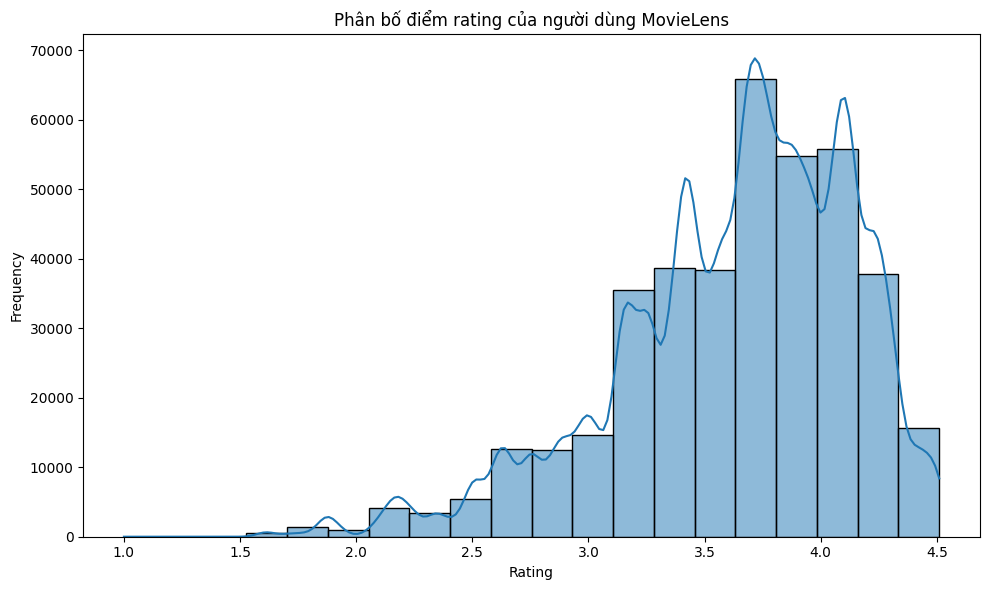

In [229]:
# Phân bố biến mục tiêu
plt.figure(figsize=(10, 6))
sns.histplot(full_data['avg_rating'], bins=20, kde=True)
plt.title('Phân bố điểm rating của người dùng MovieLens')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


Biểu đồ phân bố điểm rating cho thấy dữ liệu lệch trái rõ rệt:

+ Tần suất thấp ở các mức điểm thấp (1.0–2.5) và tăng mạnh ở các mức điểm cao. Phần lớn đánh giá tập trung trong khoảng 3.0–4.5, với các cột vượt 30.000 lượt. Đỉnh cao nhất xuất hiện tại mức 4.0, đạt khoảng 65.000–70.000 lượt, tiếp theo là các đỉnh tại 3.0 và 3.5. Sau mức 4.0, tần suất giảm dần ở 4.5. 

+ Đường cong mật độ bám sát các cột và gợn sóng theo các mức điểm nguyên và bán nguyên, phản ánh xu hướng đánh giá tập trung vào các mốc điểm quen thuộc.

In [230]:
# 2. Thống kê mô tả
print(full_data['Rating'].describe())
print(f"Skewness: {full_data['Rating'].skew():.3f}")
print(f"Kurtosis: {full_data['Rating'].kurtosis():.3f}")


count    397975.000000
mean          3.630100
std           1.106728
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: Rating, dtype: float64
Skewness: -0.591
Kurtosis: -0.292


- Kết quả thống kê mô tả cho thấy điểm rating trung bình của người dùng MovieLens đạt 3.63 trên thang điểm 5. 
Giá trị trung vị và tứ phân vị trên đều bằng 4.0, cho thấy phần lớn các bộ phim được đánh giá ở mức khá đến tốt.

- Phân bố rating có độ lệch trái nhẹ (skewness = -0.591), phản ánh xu hướng người dùng chấm điểm cao nhiều hơn điểm thấp.
Hệ số kurtosis âm (-0.293) cho thấy phân bố có đỉnh thấp và trải rộng hơn so với phân bố chuẩn, không xuất hiện hiện tượng tập trung quá mức quanh giá trị trung bình.

- Nhìn chung, phân bố rating không hoàn toàn tuân theo phân bố chuẩn nhưng không có sự lệch cực đoan, cho phép áp dụng các phương pháp phân tích thống kê và mô hình hóa trong các bước tiếp theo.


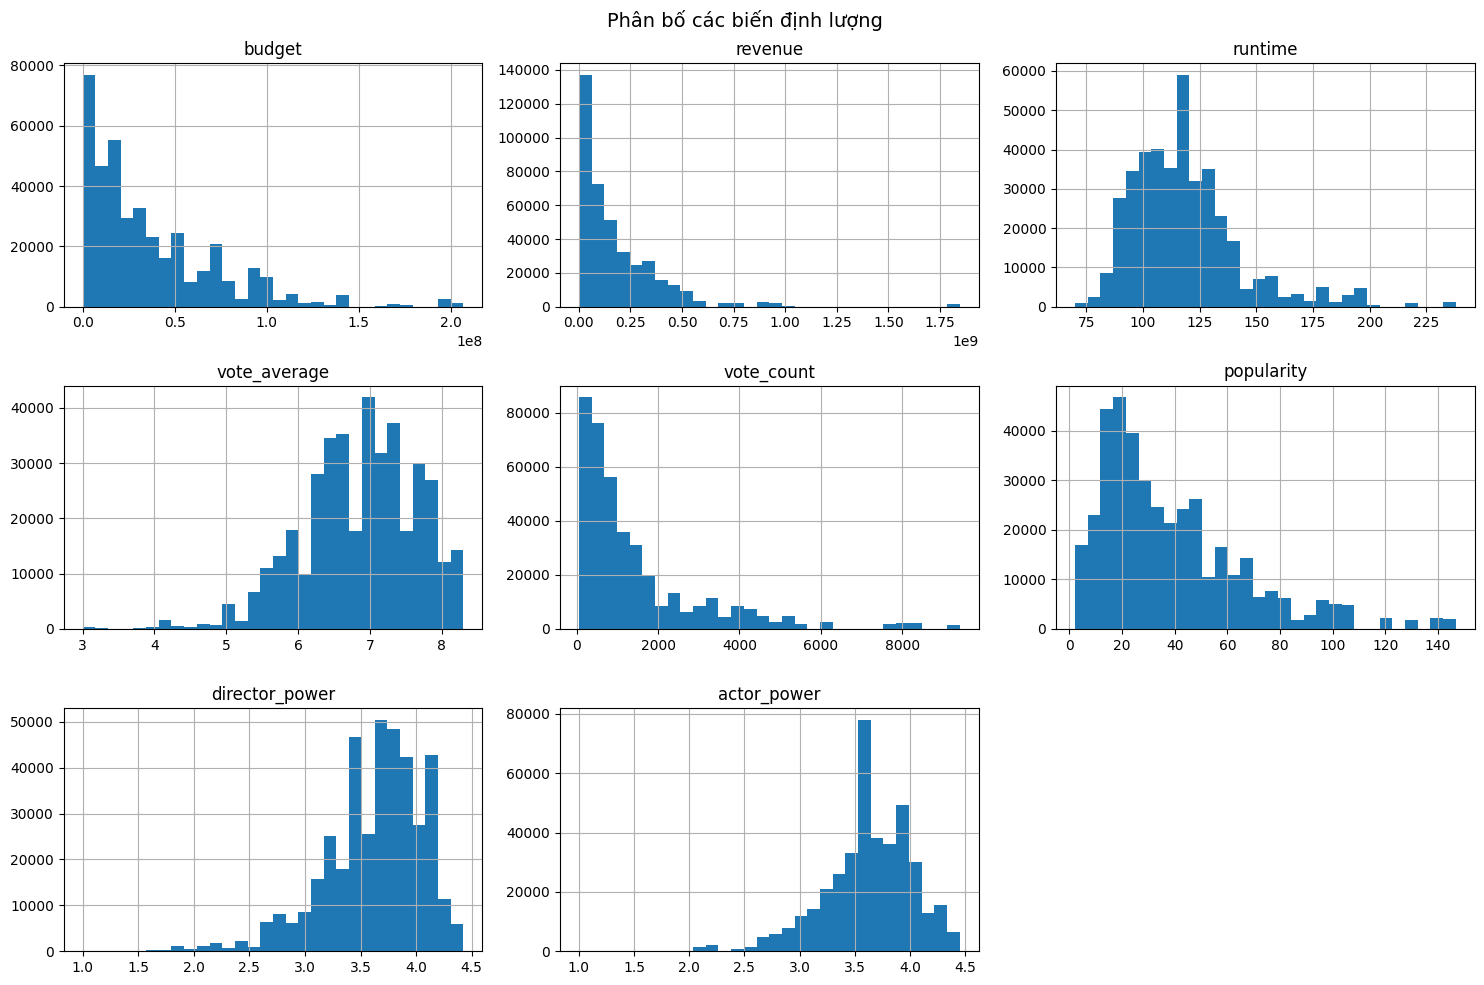

In [231]:
# 3. Phân bố các biến numerical khác
numerical_cols = [
    'budget', 
    'revenue', 
    'runtime', 
    'vote_average', 
    'vote_count',
    'popularity',
    'director_power',
    'actor_power'
]

full_data[numerical_cols].hist(figsize=(15, 10), bins=30)
plt.suptitle('Phân bố các biến định lượng', fontsize=14)
plt.tight_layout()
plt.show()


Nhóm biến lệch phải mạnh (budget, revenue, vote_count, popularity):
Các biến này đều có phân bố lệch phải rõ rệt. Phần lớn phim nằm ở mức thấp đến trung bình, trong khi chỉ một số ít phim bom tấn hoặc rất nổi tiếng có giá trị cực cao, tạo ra đuôi dài. Đây là đặc trưng phổ biến của ngành điện ảnh, phản ánh sự chênh lệch lớn giữa phim đại chúng và số ít tác phẩm dẫn đầu thị trường.

Nhóm biến tập trung và ổn định (runtime):
Thời lượng phim phân bố khá tập trung, gần dạng chuông, chủ yếu trong khoảng 90–130 phút. Điều này cho thấy thời lượng phim điện ảnh tương đối ổn định, chỉ có rất ít phim quá ngắn hoặc quá dài.

Nhóm biến phản ánh cảm nhận người xem (vote_average):
Điểm đánh giá trung bình tập trung nhiều ở khoảng 6–8 điểm, đây là điểm được chấm từ TMDB, cho thấy xu hướng người dùng đánh giá phim khá tích cực. Các mức điểm quá thấp hoặc quá cao xuất hiện ít, phản ánh sự đồng thuận tương đối trong cảm nhận chất lượng phim.

Sự xuất hiện dày đặc của các giá trị ngoại lai (outliers) ở nhóm biến tài chính và mức độ phổ biến chính là minh chứng rõ nét cho phân phối "đuôi dài" (long-tail) đặc thù của ngành công nghiệp điện ảnh. Những giá trị này không phải là nhiễu, mà đại diện cho các bộ phim "bom tấn" nằm tách biệt hoàn toàn so với mặt bằng chung, tạo ra sự chênh lệch cực lớn về quy mô và sức ảnh hưởng. Chính sự hiện diện của những ngoại lai này đã kéo dãn đồ thị về phía bên phải, gây ra hiện tượng lệch phân phối, đòi hỏi các phương pháp xử lý dữ liệu đặc thù để mô hình không bị thiên lệch bởi thiểu số các siêu phẩm này.



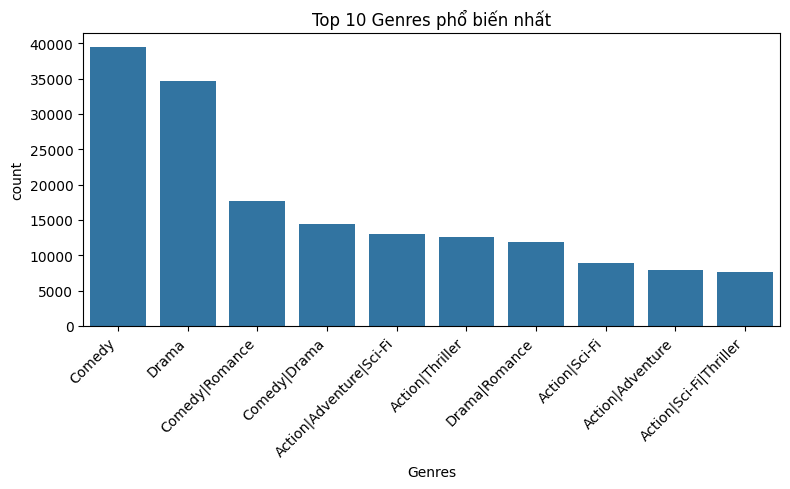

In [232]:
import seaborn as sns
import matplotlib.pyplot as plt

# 4. Tần suất của các biến phân loại
categorical_cols = ['Genres']

for col in categorical_cols:
    top_values = full_data[col].value_counts().head(10).reset_index()
    top_values.columns = [col, 'count']

    plt.figure(figsize=(8, 5))
    sns.barplot(data=top_values, x=col, y='count')
    plt.title(f'Top 10 {col} phổ biến nhất')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Genres distribution đã xác nhận có tồn tại tình trạng sự mất cân bằng trong biến phân loại (Categorical imbalance). Số lượng phim thuộc thể loại Comedy (gần 40.000) và Drama (gần 35.000) áp đảo hoàn toàn so với các thể loại phức hợp như Action|Sci-Fi|Thriller (chỉ khoảng 7.000). Sự chênh lệch lớn về tần suất xuất hiện giữa các nhóm này chính là biểu hiện rõ nhất của mất cân bằng dữ liệu, điều này sẽ ảnh hưởng lớn nếu dùng Genre làm biến mục tiêu để dự đoán.

### Phân tích hai biến

Insights cần tìm:
+ Biến nào có correlation mạnh với rating?
+ Có non-linear relationships không?

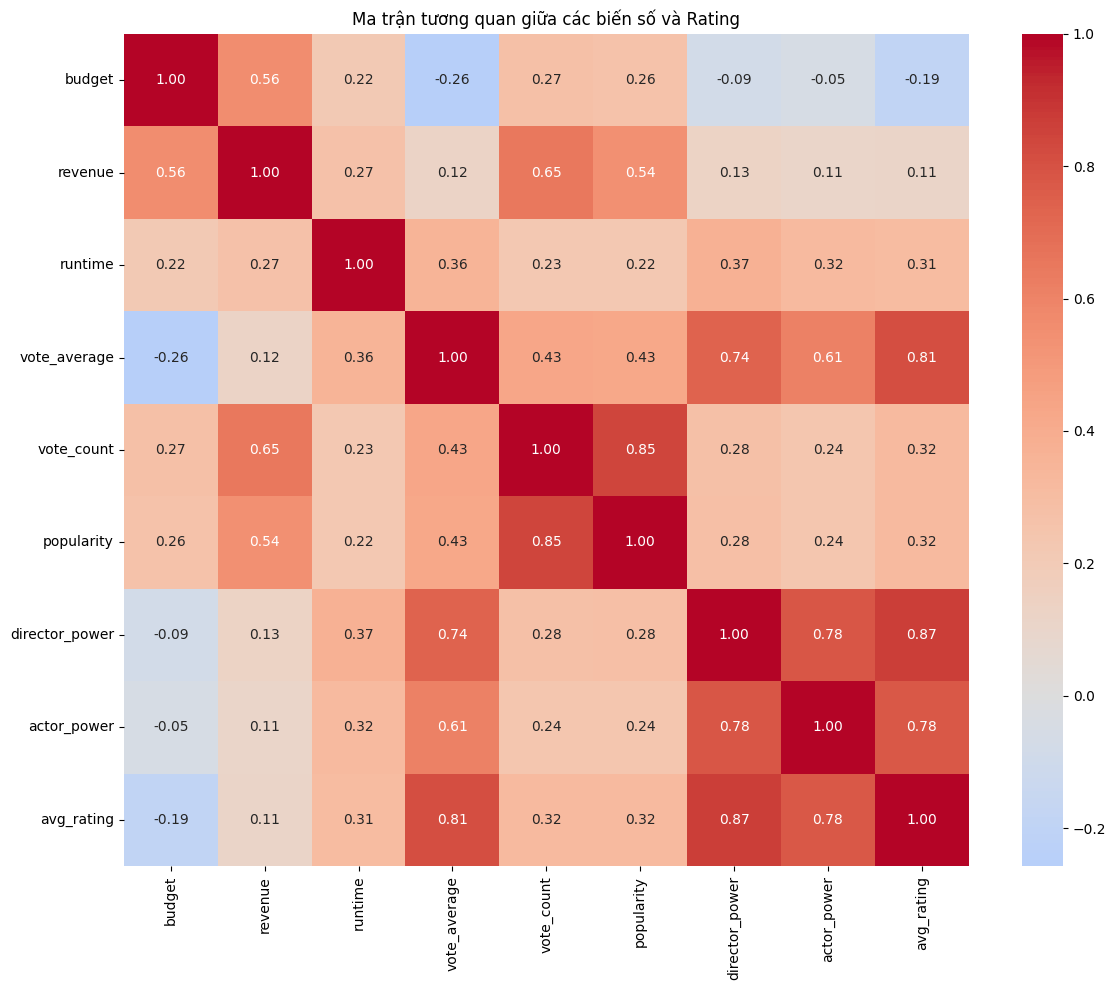

In [233]:
plt.figure(figsize=(12, 10))

corr_cols = numerical_cols + ['avg_rating']
df_movie_scope = full_data.drop_duplicates(subset=['MovieID']).copy()
correlation_matrix = df_movie_scope[corr_cols].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0
)

plt.title('Ma trận tương quan giữa các biến số và Rating')
plt.tight_layout()
plt.show()


Biến số Director Power có hệ số tương quan dương cao nhất (0.87), khẳng định rằng thương hiệu và tài năng của đạo diễn chính là "tấm tem bảo hành" uy tín nhất cho chất lượng phim trên MovieLens, quan trọng hơn rất nhiều so với số tiền đổ vào sản xuất. 

Actor Power cũng ghi nhận mức tương quan rất mạnh (0.78), cho thấy một dàn diễn viên thực lực không chỉ giúp bộ phim thu hút sự chú ý mà còn đóng góp trực tiếp vào giá trị nghệ thuật, tạo nên sự cộng hưởng mạnh mẽ giúp nâng cao điểm số đánh giá cuối cùng.

Mối tương quan cùng chiều cực mạnh (0.81) giữa avg_rating và vote_average, khẳng định rằng đánh giá của người dùng trên MovieLens rất đồng nhất với điểm số đại chúng trên TMDB. 

Điểm số trung bình cũng có mối liên hệ tích cực vừa phải với thời lượng phim (0.31) và số lượt bình chọn (0.32), gợi ý rằng các bộ phim có thời lượng dài hơn (thường là phim có chiều sâu) và được nhiều người quan tâm thường có chất lượng tốt hơn.

Ngược lại, các yếu tố tài chính lại cho thấy mối liên hệ rất yếu, thậm chí là tiêu cực với chất lượng phim:

+ Doanh thu (Revenue) gần như không ảnh hưởng đến điểm số (0.11), trong khi ngân sách (Budget) lại có tương quan âm nhẹ (-0.19). Điều này phản ánh một thực tế thú vị: phim được đầu tư "khủng" chưa chắc đã hay, thậm chí đôi khi ngân sách càng cao thì điểm đánh giá lại càng thấp hơn so với kỳ vọng.



+ Sự phụ thuộc lẫn nhau giữa các biến độc lập, chẳng hạn như phim có doanh thu cao thường đi kèm với lượng tương tác lớn (0.65) và ngân sách lớn (0.56).

Mối tương quan 0.31 giữa thời lượng và điểm số gợi mở giả thuyết rằng khán giả thường ưu ái những tác phẩm dài hơi có chiều sâu hơn là phim giải trí ngắn. Dùng boxplot để kiểm chứng:

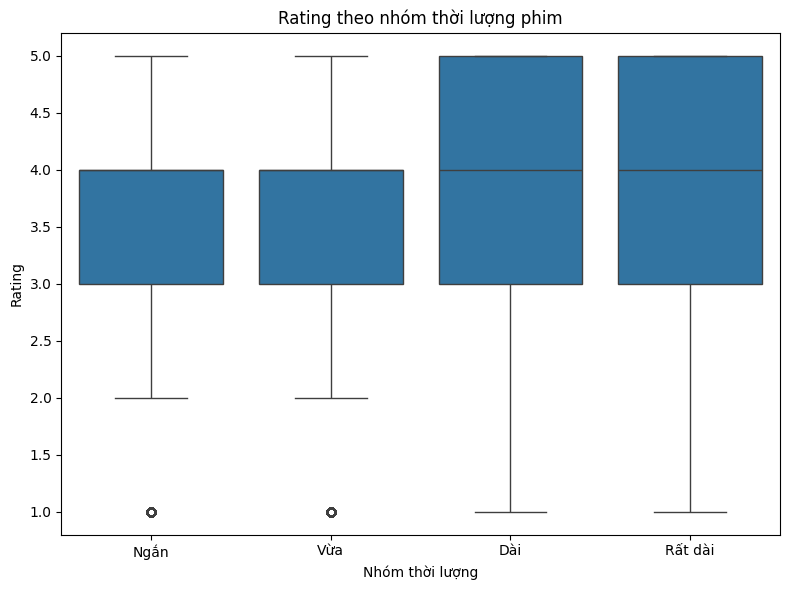

In [234]:
full_data['runtime_group'] = pd.cut(
    full_data['runtime'],
    bins=[0, 90, 120, 150, 300],
    labels=['Ngắn', 'Vừa', 'Dài', 'Rất dài']
)

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=full_data,
    x='runtime_group',
    y='Rating'
)

plt.title('Rating theo nhóm thời lượng phim')
plt.xlabel('Nhóm thời lượng')
plt.ylabel('Rating')
plt.tight_layout()
plt.show()


Nhóm phim ngắn và vừa có trung vị khoảng 3.5, với khoảng phân bố hẹp hơn, cho thấy mức đánh giá tương đối ổn định nhưng không quá cao. Một số ngoại lệ có điểm rất thấp (khoảng 1 sao) xuất hiện ở hai nhóm này.

Trong khi đó, nhóm phim dài và rất dài có trung vị cao hơn, xấp xỉ 4.0, đồng thời độ phân tán lớn hơn, phản ánh sự đa dạng trong đánh giá của người xem. Dù vẫn tồn tại các phim bị chấm điểm thấp, phần lớn phim dài và rất dài có xu hướng nhận đánh giá tích cực hơn.

Nhìn chung, kết quả cho thấy phim có thời lượng dài hơn thường được đánh giá cao hơn, có thể do nội dung được phát triển sâu hơn, dù mức độ rủi ro cũng tăng khi chất lượng không đồng đều.

Bên cạnh đó vẫn còn những yếu tố phân loại, cùng xem xét sự tương quan của nó đến rating trung bình:

+ Độ tuổi:

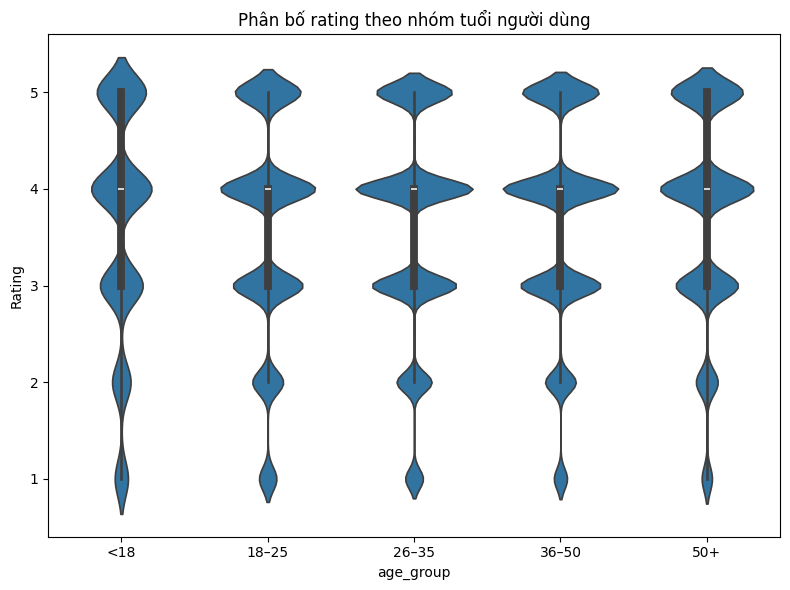

In [235]:
bins = [0, 18, 25, 35, 50, 100]
labels = ['<18', '18–25', '26–35', '36–50', '50+']

users['age_group'] = pd.cut(
    users['Age'],
    bins=bins,
    labels=labels,
    right=False
)

full_data = full_data.merge(
    users[['UserID', 'Gender', 'age_group']],
    on='UserID',
    how='left'
)

plt.figure(figsize=(8, 6))
sns.violinplot(
    data=full_data,
    x='age_group',
    y='Rating'
)

plt.title('Phân bố rating theo nhóm tuổi người dùng')
plt.tight_layout()
plt.show()

Kết quả cho thấy một sự đồng nhất đáng ngạc nhiên trong hành vi chấm điểm giữa tất cả các nhóm tuổi. Dù là nhóm trẻ nhất (<18) hay nhóm lớn tuổi nhất (50+), hình dáng của biểu đồ violin gần như y hệt nhau. Cụ thể, dữ liệu tập trung dày đặc (phần phình to nhất của biểu đồ) ở các mốc điểm 3.0, 4.0 và 5.0, trong khi phần đuôi ở các điểm thấp (1.0, 2.0) rất thon nhỏ. Giá trị trung vị (thể hiện qua chấm trắng hoặc vạch giữa) của tất cả các nhóm đều neo ổn định ở mức 4.0.

-> Tuổi tác không phải là yếu tố phân biệt mạnh đối với việc người dùng đánh giá phim cao hay thấp. Một thiếu niên và một người trung niên trong tập dữ liệu này có xu hướng "hào phóng" như nhau khi chấm điểm.


+ Giới tính:

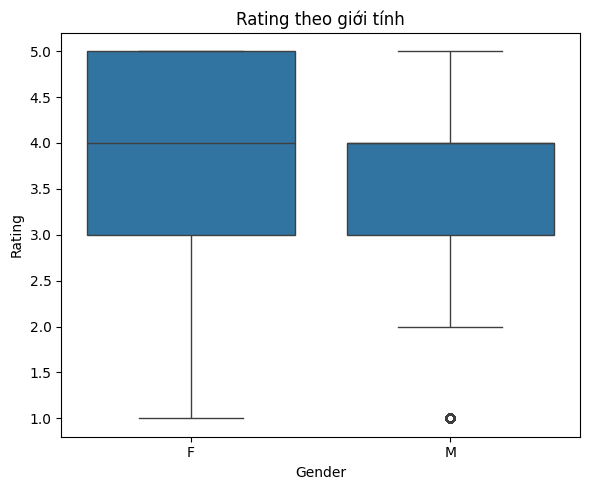

In [236]:
plt.figure(figsize=(6, 5))
sns.boxplot(
    data=full_data,
    x='Gender',
    y='Rating'
)

plt.title('Rating theo giới tính')
plt.tight_layout()
plt.show()



Trung vị (median) của cả hai giới tính đều nằm ở mức 4.0 (đường gạch ngang giữa hộp). Tuy nhiên, sự khác biệt bắt đầu lộ diện ở độ rộng của hộp (Interquartile Range - IQR). Nhóm Nữ (F) có vùng dữ liệu tập trung trải rộng hơn từ 3.0 đến 5.0, trong khi nhóm Nam (M) lại co cụm hẹp hơn chỉ từ 3.0 đến 4.0.

Cho thấy Nữ giới có xu hướng "hào phóng" hoặc phân cực hơn trong việc chấm điểm; họ sẵn sàng cho điểm tuyệt đối (5.0) nhiều hơn, khiến cạnh trên của hộp chạm mốc tối đa. Ngược lại, Nam giới tỏ ra thận trọng và khắt khe hơn, điểm số của họ ổn định cao ở mức khá (3-4 điểm) nhưng ít khi chạm ngưỡng xuất sắc trong nhóm phổ thông (75% dữ liệu nằm dưới mức 4.0). 

-> Mặc dù không quá lớn, nhưng sự khác biệt về phương sai (variance) này cho thấy biến user_gender có giá trị hơn so với age_group. Mô hình có thể học được rằng nếu là user nữ, xác suất xuất hiện điểm 5.0 sẽ nhỉnh hơn so với user nam.

+ Thể loại:

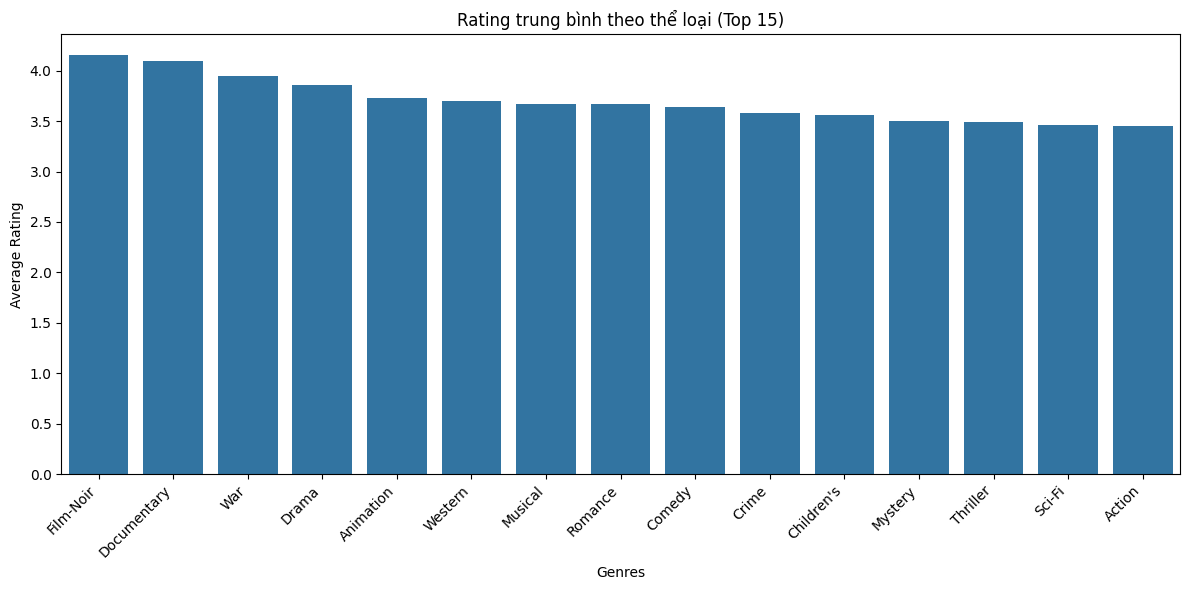

In [237]:
genre_df = full_data[['Genres', 'Rating']].copy()
genre_df['Genres'] = genre_df['Genres'].str.split('|')
genre_df = genre_df.explode('Genres')

genre_rating = genre_df.groupby('Genres')['Rating'].agg(
    mean='mean',
    count='count',
    std='std'
)

genre_rating = genre_rating[genre_rating['count'] > 1000] \
    .sort_values('mean', ascending=False) \
    .head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=genre_rating.index,
    y=genre_rating['mean']
)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Average Rating')
plt.title('Rating trung bình theo thể loại (Top 15)')
plt.tight_layout()
plt.show()


Nhóm thể loại có điểm trung bình cao nhất là Film-Noir và Documentary, đều đạt trên 4.0, cho thấy các phim thuộc nhóm này thường được đánh giá cao về nội dung và chiều sâu. Tiếp theo là War và Drama, với mức rating xấp xỉ từ 3.9 đến 4.0, phản ánh sự đánh giá tích cực của người xem đối với các thể loại giàu tính cảm xúc và giá trị nghệ thuật.

Các thể loại phổ biến như Animation, Western, Musical, Romance và Comedy có rating trung bình dao động quanh 3.6–3.7, thể hiện mức độ hài lòng khá tốt nhưng không nổi trội.

Ở nhóm cuối, Action, Sci-Fi, Thriller và Mystery có rating trung bình thấp hơn, khoảng 3.4–3.5. Điều này cho thấy dù thu hút đông đảo khán giả, các thể loại thiên về giải trí và kỹ xảo thường khó đạt điểm đánh giá cao như những thể loại chú trọng nội dung và thông điệp.

Cho thấy khán giả MovieLens có xu hướng đánh giá khắt khe hơn với các dòng phim thị trường (Action, Sci-Fi) và dành sự trân trọng đặc biệt cho các tác phẩm nghệ thuật hoặc phim tài liệu. Một bộ phim "Film-Noir" ngẫu nhiên có xác suất được đánh giá cao hơn nhiều so với một bộ phim "Action" ngẫu nhiên.

-> Khác với biến độ tuổi (Age Group) gần như phẳng lì, biến Genre cho thấy khả năng phân loại (discriminative power) rất tốt. Việc biết một bộ phim thuộc thể loại Documentary hay Action sẽ thay đổi đáng kể kỳ vọng về điểm số. Do đó, đây chắc chắn là một biến quan trọng (high feature importance) cần được xử lý kỹ (ví dụ: One-Hot Encoding hoặc Target Encoding) để đưa vào mô hình.

Trong heatmap, budget có tương quan âm nhẹ (-0.19) với rating, nhưng điều này không có nghĩa là cứ giảm tiền thì phim sẽ hay. Rất có thể mối quan hệ này mang hình dạng đường cong (curvilinear) hoặc có điểm bão hòa:

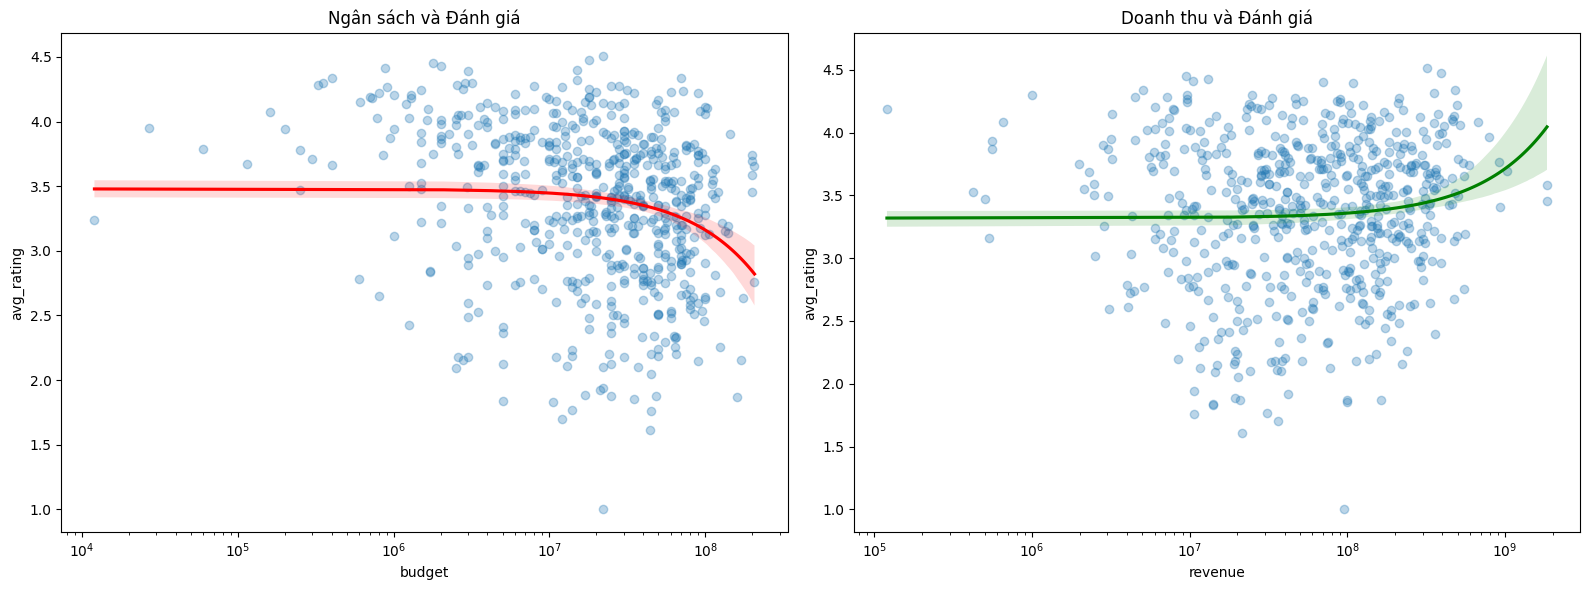

In [238]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_movie_scope, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.show()

Hiệu ứng ngược của Ngân sách (Đường đỏ): Xuất hiện xu hướng phi tuyến tính rõ rệt. Điểm đánh giá đi ngang ở mức ngân sách thấp và trung bình, nhưng bắt đầu giảm dần khi ngân sách tăng lên mức cực cao (trên $10^8$). Điều này cho thấy các phim "bom tấn" kinh phí khủng thường không được đánh giá cao về chất lượng nội dung.

Sự đồng thuận của Doanh thu (Đường xanh): Có mối quan hệ tương quan dương phi tuyến tính. Doanh thu càng cao, đường xu hướng càng đi lên, chứng tỏ các bộ phim thành công về mặt thương mại thường cũng là những phim có chất lượng tốt và được khán giả yêu thích.

Tính phi tuyến tính hiện diện rõ rệt qua hai đường cong đối lập trên biểu đồ. Trong khi ngân sách tuân theo quy luật "hiệu suất giảm dần" với đường xu hướng uốn xuống ở mức đầu tư siêu cao, thì doanh thu lại vẽ nên đường cong dốc lên, cho thấy sự đồng biến mạnh mẽ với chất lượng ở phân khúc "tỷ đô". Từ đó rút ra: "Tiền không mua được chất lượng nghệ thuật". Có một ngưỡng chi phí "tối ưu" (khoảng 10-50 triệu USD) nơi các nhà làm phim cân bằng tốt nhất giữa chất lượng sản xuất và tự do sáng tạo. Vượt qua ngưỡng này, áp lực thương mại khiến nội dung trở nên an toàn và sáo rỗng, kéo tụt điểm số.

### Phân tích đa biến

Insights cần tìm:
+ Có interaction effects không? (VD: budget cao + action genre = rating cao)

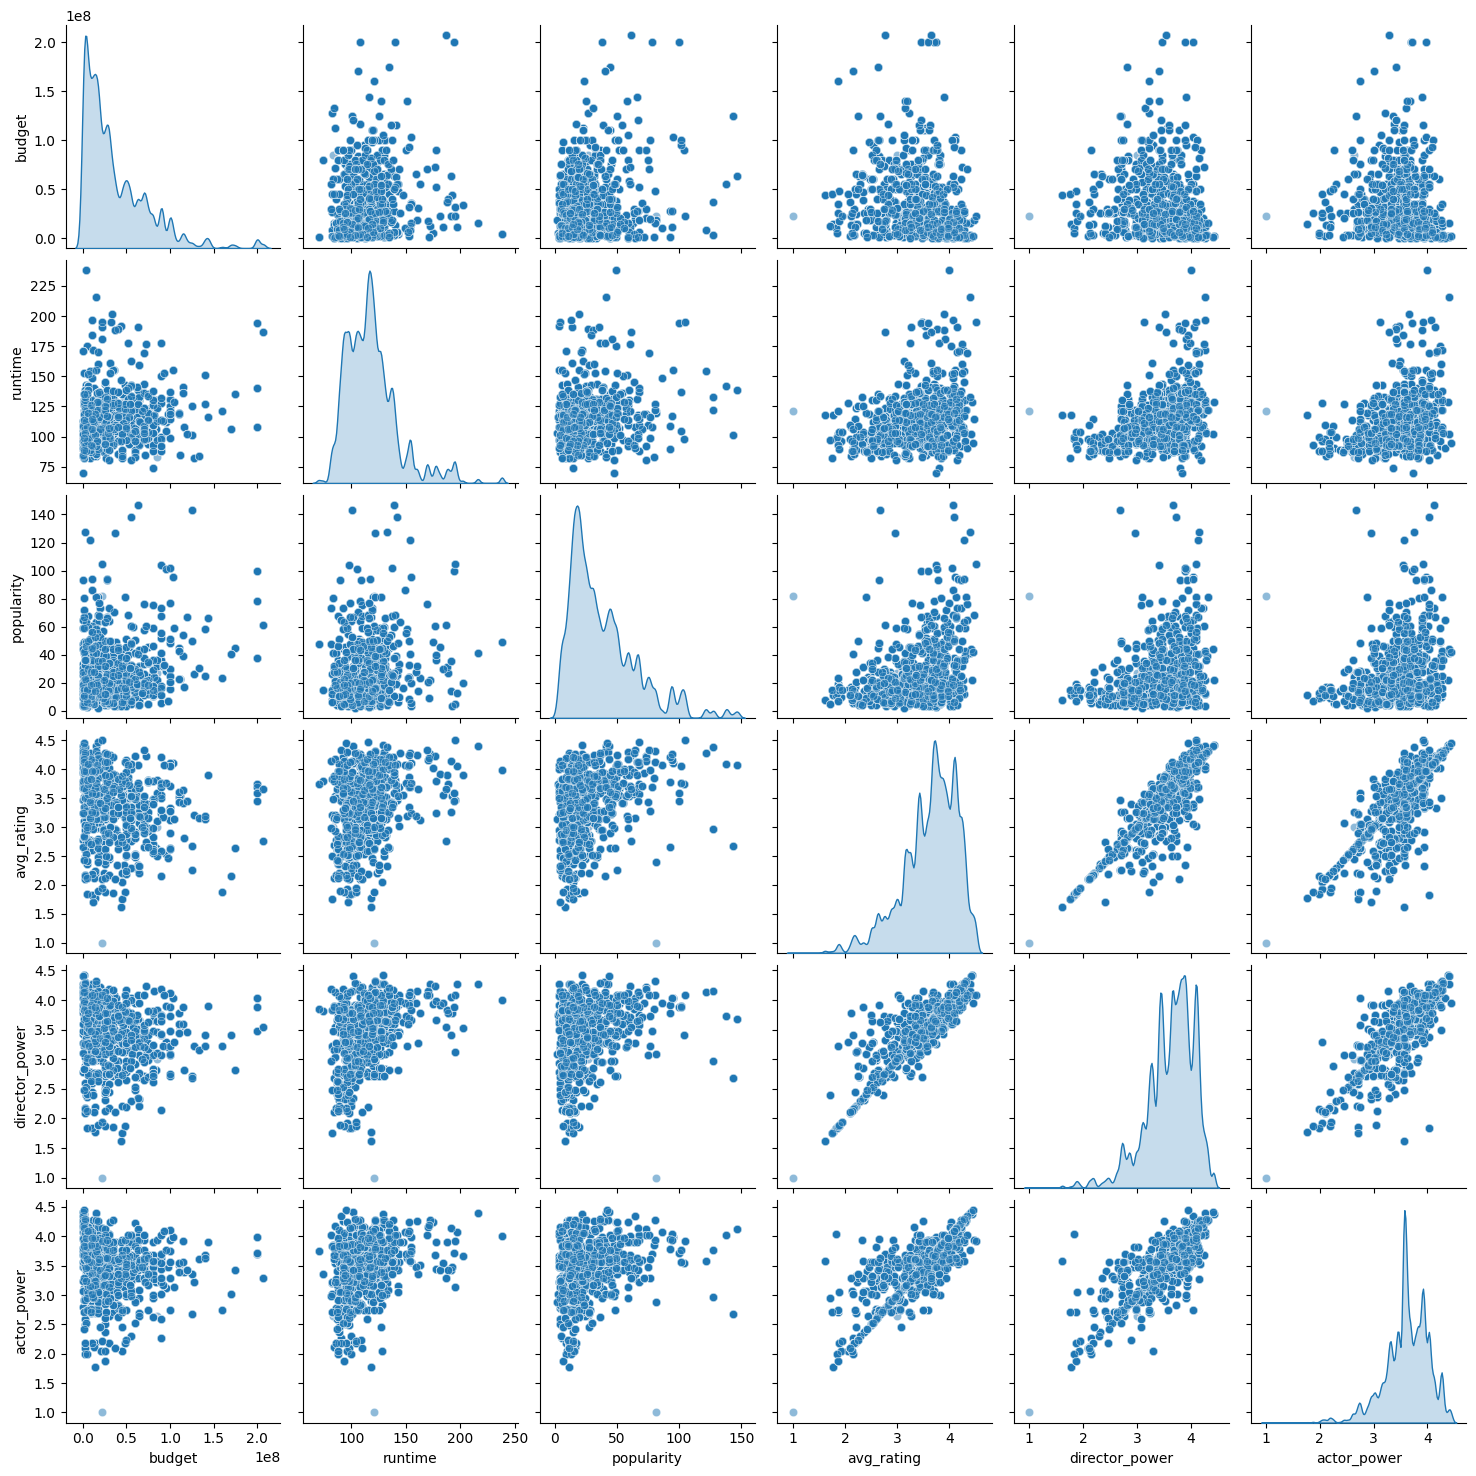

In [243]:
# 1. Pairplot cho top features
top_features = ['budget', 'runtime', 'popularity', 'avg_rating', 'director_power', 'actor_power']
sns.pairplot(full_data[top_features], diag_kind='kde', plot_kws={'alpha': 0.5})
plt.show()

Dữ liệu đã chứng minh tiền bạc có thể mua được sự nổi tiếng nhưng không thể mua được điểm số cao. Mối quan hệ giữa ngân sách và chất lượng hoàn toàn lỏng lẻo, cho thấy khán giả quan tâm đến trải nghiệm nội dung hơn là quy mô sản xuất. Ngược lại, thời lượng và độ phổ biến đang cho thấy những tín hiệu hứa hẹn hơn để giải thích cho sự thành công của một bộ phim.

Mối quan hệ giữa Sức mạnh Đạo diễn và Điểm đánh giá tạo thành một dải hẹp dốc lên rất rõ nét, khẳng định đây là yếu tố dự báo chính xác nhất cho chất lượng phim. Tương tự, Sức mạnh Diễn viên cũng song hành chặt chẽ với điểm số, và thú vị hơn là sự tương quan mạnh giữa chính Đạo diễn và Diễn viên, cho thấy tài năng thường có xu hướng hội tụ để cùng tạo nên những tác phẩm xuất sắc, tách biệt hoàn toàn với sự ngẫu nhiên của yếu tố tài chính.

Vậy bên cạnh yếu tố như đạo diễn hay diễn viên, yếu tố nào còn góp phần thúc đẩy rating? Là giá trị nội tại của câu chuyện (đại diện bởi Thời lượng) hay sức ép từ hào quang bên ngoài (đại diện bởi Độ phổ biến)? Phân tích bộ 3 avg_rating, runtime và popularity để làm rõ.

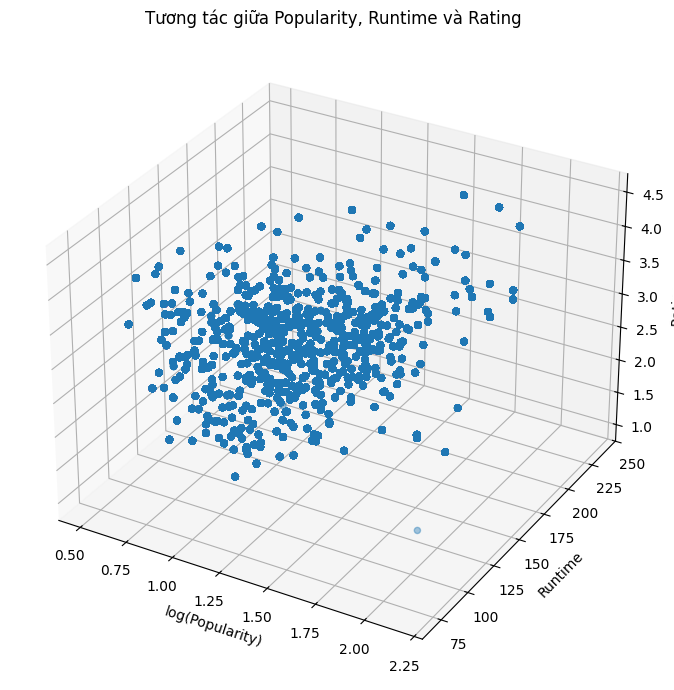

In [240]:
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    np.log10(full_data['popularity'] + 1),
    full_data['runtime'],
    full_data['avg_rating'],
    alpha=0.4
)

ax.set_xlabel('log(Popularity)')
ax.set_ylabel('Runtime')
ax.set_zlabel('Rating')

plt.title('Tương tác giữa Popularity, Runtime và Rating')
plt.tight_layout()
plt.show()


Sự hội tụ dữ liệu: có cấu trúc tập trung rõ rệt. Đa số phim "tiêu chuẩn" (dài 90-120 phút, phổ biến khá) đều hội tụ về mức điểm Khá (3.0 - 3.5).

Độ phổ biến là "lưới an toàn": Phim càng nổi tiếng càng hiếm khi bị điểm thấp. Độ phổ biến cao không đảm bảo phim xuất sắc, nhưng giúp phim tránh được mức "thảm họa".

Chân dung "Siêu phẩm" (>4.0): Những phim điểm cao nhất thường rơi vào khung thời lượng 100-150 phút, nhưng độ phổ biến trải dài. Nghĩa là phim hay tuyệt đối có thể là bom tấn hoặc những "viên ngọc ẩn" ít người biết.



Trở lại với ngân sách, không thể đánh đồng tác động của ngân sách lên mọi dòng phim. Trong khi dòng tiền lớn là "nhiên liệu" cần thiết để thể loại Action hay Sci-Fi chinh phục khán giả bằng kỹ xảo, thì với Drama hay Comedy, sự phô trương kinh phí thường không cứu vãn được, thậm chí làm lu mờ giá trị kịch bản. Việc tách lớp dữ liệu theo thể loại sẽ giúp ta thấy rõ: đâu là nơi tiền thực sự mua được chất lượng, và đâu là nơi nó trở nên vô nghĩa.

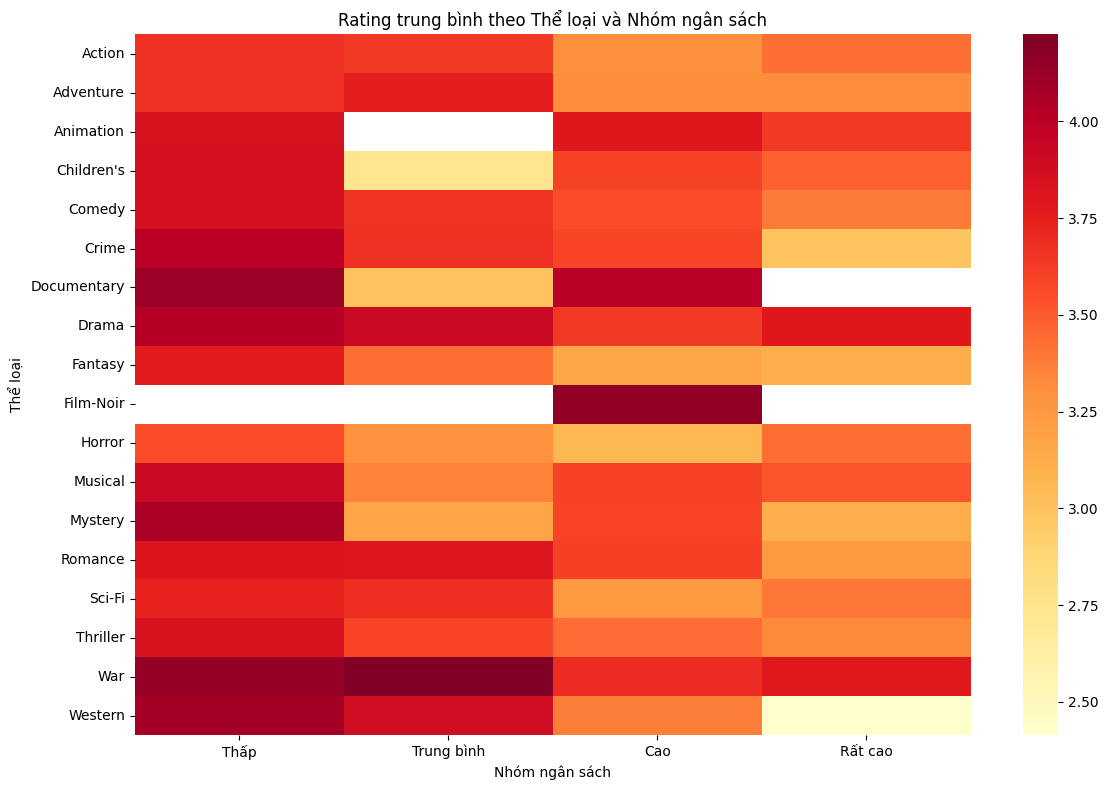

In [241]:
# 2. Rating theo genre và budget_category
# Tạo budget_category
full_data['budget_category'] = pd.qcut(
    full_data['budget'],
    q=4,
    labels=['Thấp', 'Trung bình', 'Cao', 'Rất cao']
)

# Xử lý genres
genre_budget_df = full_data[['Genres', 'budget_category', 'avg_rating']].copy()
genre_budget_df['Genres'] = genre_budget_df['Genres'].str.split('|')
genre_budget_df = genre_budget_df.explode('Genres')

pivot_table = genre_budget_df.pivot_table(
    values='avg_rating',
    index='Genres',
    columns='budget_category',
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(
    pivot_table,
    cmap='YlOrRd',
    annot=False
)

plt.title('Rating trung bình theo Thể loại và Nhóm ngân sách')
plt.ylabel('Thể loại')
plt.xlabel('Nhóm ngân sách')
plt.tight_layout()
plt.show()


Ngân sách là "Nhiên liệu" hay "Gánh nặng"?

Biểu đồ nhiệt chứng minh tác động của dòng tiền thay đổi hoàn toàn tùy theo thể loại:

+ Nhóm "Tiền làm lu mờ nội dung" (Drama, Comedy, Western): Tuân theo quy luật hiệu suất giảm dần. Ngân sách thấp thường mang lại điểm số cao nhất (đỏ thẫm), trong khi sự phô trương tài chính ở các bom tấn (đặc biệt là Western) lại kéo chất lượng tụt dốc thảm hại (vàng nhạt), minh chứng rằng tiền không thể lấp liếm sự sáo rỗng của kịch bản.

+ Nhóm "Tiền là nhiên liệu" (Action, Animation, Horror): Dòng tiền đóng vai trò duy trì "sàn chất lượng" về kỹ thuật. Trong khi Action giữ phong độ ổn định, thì Animation và Horror lại có sự bứt phá ngoạn mục ở phân khúc siêu bom tấn, thoát khỏi "vùng chết" chất lượng kém ở mức ngân sách trung bình.

-> Thể loại (Genre) chính là lăng kính quan trọng nhất. Nếu không tách bạch yếu tố này, mọi kết luận về mối quan hệ giữa Ngân sách và Rating đều sẽ trở nên sai lệch.

## Phân tích Chuyên sâu - Các yếu tố ảnh hưởng Rating

1. Yếu tố Tài chính: Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

2. Yếu tố Nội dung & Cấu trúc: Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

3. Yếu tố Nhân sự & Thời gian: Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?